In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re
from collections import Counter 

In [2]:
current_dir = os.getcwd()
parent_dir = os.path.dirname(current_dir)

DATA_PATH = os.path.join(parent_dir, 'data', 'synthetic_dataset.json')
with open(DATA_PATH, 'r', encoding='utf-8') as f:
    data = json.load(f)
df = pd.DataFrame(data)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 529 entries, 0 to 528
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   text           529 non-null    str  
 1   event_type     529 non-null    str  
 2   address        437 non-null    str  
 3   is_actionable  529 non-null    bool 
 4   is_planned     529 non-null    bool 
dtypes: bool(2), str(3)
memory usage: 13.6 KB


                            Count  Percentage (%)
event_type                                       
планові/аварійні ремонти      120           22.68
шум                           101           19.09
транспортні інциденти          88           16.64
відключення інфраструктури     87           16.45
погодні негаразди              81           15.31
культурні події                52            9.83


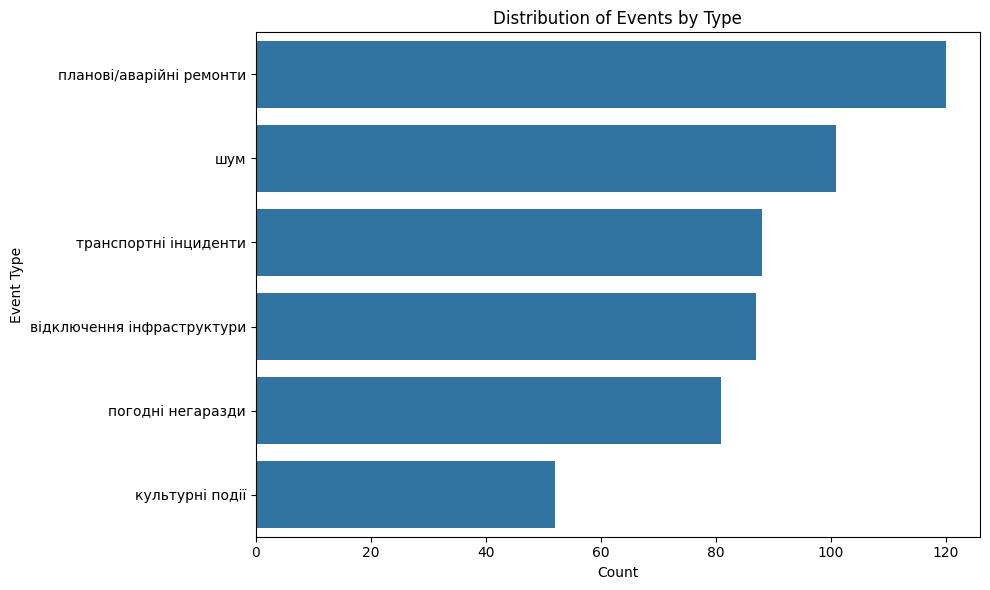

In [3]:
event_counts = df['event_type'].value_counts()
event_percent = df['event_type'].value_counts(normalize=True) * 100

print(pd.concat([event_counts, event_percent.round(2)], axis=1,
                keys=['Count', 'Percentage (%)']))

plt.figure(figsize=(10, 6))
sns.countplot(data=df, y='event_type', order=event_counts.index)
plt.title('Distribution of Events by Type')
plt.xlabel('Count')
plt.ylabel('Event Type')
plt.tight_layout()
plt.show()

In [8]:
print(df['is_actionable'].value_counts())
print(df['is_actionable'].value_counts(normalize=True).round(4) * 100)

is_actionable
True     436
False     93
Name: count, dtype: int64
is_actionable
True     82.42
False    17.58
Name: proportion, dtype: float64


In [9]:
print(df['is_planned'].value_counts())
print(df['is_planned'].value_counts(normalize=True).round(4) * 100)

is_planned
False    370
True     159
Name: count, dtype: int64
is_planned
False    69.94
True     30.06
Name: proportion, dtype: float64


In [10]:
cross = pd.crosstab(df['is_planned'], df['is_actionable'], normalize='all') * 100
print(cross.round(2))

is_actionable  False  True 
is_planned                 
False          17.58  52.36
True            0.00  30.06


In [4]:
print(f"Records with address: {df['address'].notna().sum()} ({df['address'].notna().mean()*100:.1f}%)")
print(f"Records without address: {df['address'].isna().sum()}")

print("\nTop-15 most frequent addresses:")
print(df['address'].value_counts().head(15))

Records with address: 437 (82.6%)
Records without address: 92

Top-15 most frequent addresses:
address
вул. Хрещатик                       14
вул. Ревуцького, Позняки             5
просп. Оболонський, Оболонь          5
вул. Полярна, Лісовий масив          5
просп. Науки                         5
ВДНГ                                 4
просп. Відрадний                     4
вул. Деміївська, Деміївка            4
вул. Нікопольська, Святошин          4
Андріївський узвіз, Поділ            4
Гідропарк                            4
вул. Теремківська, Теремки           4
міст Патона                          3
вул. Антоновича                      3
вул. Героїв Сталінграда, Оболонь     3
Name: count, dtype: int64


count    529.0
mean     162.6
std       87.0
min       63.0
25%       87.0
50%       97.0
75%      256.0
max      333.0
Name: text_length, dtype: float64


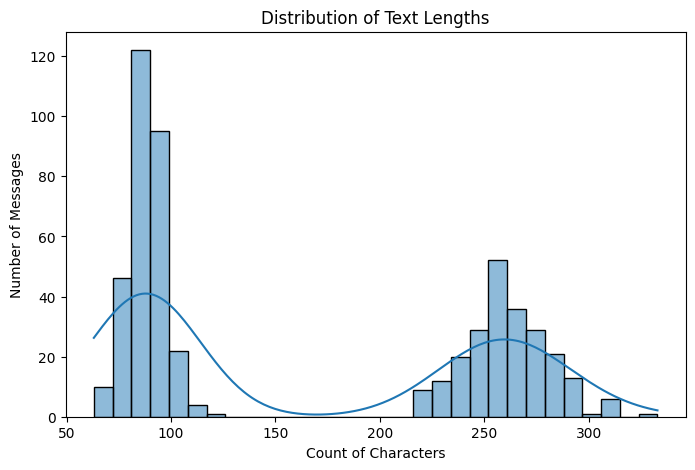

In [5]:
df['text_length'] = df['text'].str.len()
print(df['text_length'].describe().round(1))

plt.figure(figsize=(8, 5))
sns.histplot(df['text_length'], bins=30, kde=True)
plt.title('Distribution of Text Lengths')
plt.xlabel('Count of Characters')
plt.ylabel('Number of Messages')
plt.show()

In [7]:
def clean_text(text):
    text = re.sub(r'[^а-яА-ЯїієїґҐ\s]', ' ', text.lower())
    return text.split()

all_words = []
for text in df['text']:
    all_words.extend(clean_text(text))

word_freq = Counter(all_words)
print("\nTop-20 most frequent words:")
print(word_freq.most_common(20))


Top-20 most frequent words:
[('на', 560), ('вул', 243), ('з', 232), ('року', 224), ('у', 220), ('о', 191), ('до', 181), ('та', 149), ('про', 143), ('травня', 107), ('червня', 104), ('що', 98), ('повідомляє', 94), ('кмда', 94), ('роботи', 93), ('просп', 90), ('рух', 84), ('інформує', 79), ('кп', 74), ('район', 73)]
